In [1]:
# Initialize Otter
import otter
grader = otter.Notebook("hwk3-task2-spills.ipynb")

/opt/anaconda3/envs/eds220-env/lib/python3.11/site-packages/nbformat/validator.py:434: DuplicateCellId: Non-unique cell id '4d52d6d9-e745-43b4-9320-6f54aa03165d' detected. Corrected to 'ff8b6b12'.
  _validate(nbdict, ref, version, version_minor, relax_add_props)
/opt/anaconda3/envs/eds220-env/lib/python3.11/site-packages/nbformat/validator.py:434: DuplicateCellId: Non-unique cell id 'cb27288e-e39c-424a-a6d9-91246bc5ccb8' detected. Corrected to '62ca6af6'.
  _validate(nbdict, ref, version, version_minor, relax_add_props)


# Task 2: Visualizing oil spills in NY State

## Instructions

- First, update the following cell to have a link to *your* Homework 3 GitHub repository:

**UPDATE THIS LINK**
https://github.com/ethan-mathews24/eds220-hwk3


- Review the [complete rubric for this task](https://docs.google.com/document/d/1Ce4EO3MEHW5uLks4x8BECWlkim2bcmxB4f8Qo4z26z8/edit?usp=sharing) before starting.

- **Meaningful commits should be made every time you finish a major step.** We'll check your repository and view the commit history.

- Comment mindfully in a way that enriches your code. Comments should follow best practices.

- **Do not update the top cell with the `otter` import**, this is used internally for grading.


## About the data
In this task you will use two datasets:

### First dataset: oil spills data

The first dataset contains information about [spilling incidents in the state of New York](https://data.ny.gov/Energy-Environment/Spill-Incidents/u44d-k5fk). Make sure you study the data portal and understand what each row represents before starting to code. 
You will find extra information and metadata for this dataset in the `NYSDEC_SpillIncidents_Overview.pdf` and `NYSDEC_SpillIncidents_DataDictionary.pdf` documents available at the portal.

### Second dataset: TIGER shapefile

The second dataset is the [2026 Counties (and equivalent) TIGER shapefile](https://www.census.gov/geographies/mapping-files/time-series/geo/tiger-line-file.2026.html) (file `tl_2026_us_county.zip`) from the Census Bureau. You can check the [metadata for all the TIGER shapefiles here](https://www.census.gov/programs-surveys/geography/technical-documentation/complete-technical-documentation/tiger-geo-line.html). 

### COMPLETE WORKFLOW
You will use the next code cell to complete the last exercise in the task. Leave it blank for now.

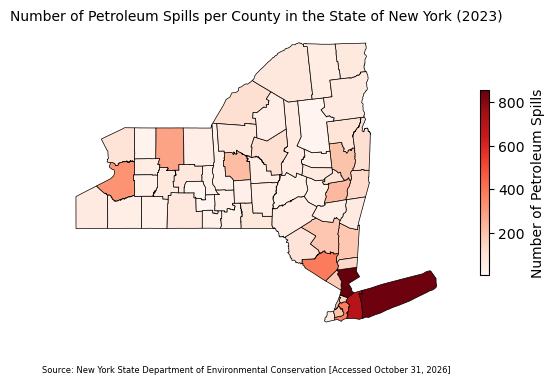

In [42]:
# FINAL CODE



# Import libraries for analysis
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import geopandas as gpd


# Load in spill data
fp = os.path.join('data', 'Spill_incidents_20261031.csv')
spills = pd.read_csv(fp)

# Load in county shapefile
fp = os.path.join('data', 'tl_2026_us_county', 'tl_2026_us_county.shp')
counties = gpd.read_file(fp)



# Prepare spill data

# Simplifies column names to follow consistent format 
spills.columns = spills.columns.str.lower().str.strip().str.replace(' ', '_')

# Update column data types
column_list = ['spill_date', 'received_date', 'close_date']

# Create a for-loop to update data types in date columns
for column in column_list:
    spills[column] = pd.to_datetime(spills[column])

# Update quantity to float
spills['quantity'] = spills['quantity'].str.replace(',','').astype(float)
    
# Update recovered to float
spills['recovered'] = spills['recovered'].str.replace(',','').astype(float)

# Filtering data for only petroleum and specific date range
petr_23 = spills[(spills['material_family'] == "Petroleum") & (spills['spill_date'] >= "2023-01-01") & (spills['spill_date'] <= "2023-12-31")]

# Group by county and count number of petroleum spills
spills_per_county = petr_23.groupby('county', as_index = False).nunique()[['county', 'spill_number']].rename(columns={'spill_number': 'n_spills'})



# Prepare county data

# Make column names lowercase
counties.columns = counties.columns.str.lower().str.strip()

# Subset to only New York 
ny_counties = counties[counties['statefp'] == '36']



# Merge DataFrames

# Create dictionary
lawr_rename = {'St Lawrence' : 'St. Lawrence'}

# Update St Lawrence to St. Lawrence in county column
spills_per_county['county'] = spills_per_county['county'].replace(lawr_rename)

# rename column name to make consistent
ny_counties = ny_counties.rename(columns = {'name':'county'})

# Create new variable of joined DataFrames
ny_spills = pd.merge(ny_counties, spills_per_county, how = 'inner', on = 'county')

# Getting the number of spills in Tuscarora
tusc_spills = spills_per_county.loc[spills_per_county['county'] == 'Tuscarora Indian Reservation', 'n_spills'].sum()

# Adding these spills to Niagara county in ny_spills
ny_spills.loc[ny_spills['county'] == 'Niagara', 'n_spills'] = ny_spills.loc[ny_spills['county'] == 'Niagara', 'n_spills'] + tusc_spills

# Getting the number of spills in Onondaga
ono_spills = spills_per_county.loc[spills_per_county['county'] == 'Onondaga Indian Reservation', 'n_spills'].sum()

# Adding these spills to Onondaga county in ny_spills
ny_spills.loc[ny_spills['county'] == 'Onondaga', 'n_spills'] = ny_spills.loc[ny_spills['county'] == 'Onondaga', 'n_spills'] + ono_spills



# Map

# Initialize empty figure and axes
fig, ax = plt.subplots()

# Plot petroleum spills in New York
ny_spills.plot(column = 'n_spills',                                                          # specify which value to plot
               cmap = 'Reds',                                                                # specify color scheme
               edgecolor = 'Black',                                                          # customizing county boundary color
               linewidth = 0.5,                                                              # customizing line width
               legend = True,                                                                # adding legend
               legend_kwds={'label': 'Number of Petroleum Spills', 'shrink' : 0.5},          # adding title to legend and changing size
               ax = ax)                     


# Remove axis
ax.axis('off')

# Add title
ax.set_title('Number of Petroleum Spills per County in the State of New York (2023)', fontsize = 10)

# Add data source
fig.text(0.1, 0.1, 'Source: New York State Department of Environmental Conservation [Accessed October 31, 2026]', fontsize = 6)

# Display map
plt.show()

## 1. File management
a. Any data you download should go in the `data/` folder of your `eds220-hwk3` repository. For example, after downloading both datasets, your repository should look like this:

```
eds220-hwk3/
├── data/
│   ├── q5d_df.csv
│   ├── Spill_Incidents_20261027.csv
│   └── tl_2026_us_county/
│       ├── tl_2026_us_county.cpg
│       ├── tl_2026_us_county.dbf
│       ├── tl_2026_us_county.prj
│       ├── tl_2026_us_county.shp
│       └── ... (other files from the shapefile)
├── tests/
├── .gitignore
├── LICENSE
├── README.md
└── hwk3-task2-spills.ipynb
```

The date in the name of the spills file may be different, depending on when you download it. `data/q5d_df.csv` is already in the repository and is used by the autograder tests, so do not delete or move it.

**IMPORTANT: Do not commit your data!**

The datasets we'll be working with are large and will most likely jam your commit history if git does not ignore them.

b. Add the relative path of each dataset you downloaded to your `.gitignore` file. For example, to ignore the folder containing the shapefile, add `data/tl_2026_us_county/` to the `.gitignore`.

c. Commit and push your changes to the `.gitignore`.

d. Run `git status` and verify that none of your data is being tracked by git.

## 2. Datasets description
- Read the metadata for both datasets and write a brief description about each one. Indicate the data sources and date of access.

### **Dataset One:** Spill Incidents
**Managed by:** New York State Department of Environmental Conservation, Division of Environmental Remediation

> The Spill Incidents dataset provided by the New York State Department of Environmental Conservation was last updated on October 31, 2026. It contains records of spills of petroleum and other hazardous materials. Under state law and federal regulations, spills that could pollute the lands or waters must be reported by the responsible party and, in some cases, by anyone with knowledge of them. Each record includes administrative information (DEC region and unique seven-digit spill number), program facility name, spill date/time, location, spill source/cause, material(s) spilled, quantity spilled/recovered, units measured, water bodies affected, and close date (cleanup activity finished).

**Date of Access:** October 31, 2026

**Source:** New York State Department of Environmental Conservation. (2026). *Spill incidents* [Data set]. New York State Open Data. Retrieved October 31, 2026, from https://data.ny.gov/Energy-Environment/Spill-Incidents/u44d-k5fk

### **Dataset Two:** 2026 TIGER/Line Shapefiles: Counties (and equivalent)
**Managed by:** United States Census Bureau

> The 2026 TIGER/Line Counties shapefile, provided by the U.S. Census Bureau, contains boundaries for counties and county-equivalent entities, such as parishes in Louisiana, boroughs and census areas in Alaska, independent cities in Maryland, Missouri, Nevada, and Virginia, and comparable divisions in U.S. territories. Together, these entities cover the entire United States, Puerto Rico, and the Island Areas. Boundaries are mostly current as of January 1, 2026, as reported through the Census Bureau’s Boundary.

**Date of Access:** October 31, 2026

**Source:** U.S. Census Bureau. (2026). *2026 TIGER/Line shapefiles: Counties (and equivalent)* [Data set]. U.S. Department of Commerce. Retrieved October 31, 2026, from https://www.census.gov/cgi-bin/geo/shapefiles/index.php?year=2026&layergroup=Counties+%28and+equivalent%29

## 3. Import libraries

In [3]:
# Import libraries for analysis
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import geopandas as gpd

## 4. Import data 
In the next cell:

- Import the NY spills data as a variable named `spills`. 
- Import the US counties data as a variable named `counties`.

If you are using file paths to access the data, these should be constructed using the `os` package.

In [4]:
# Load in spill data
fp = os.path.join('data', 'Spill_incidents_20261031.csv')
spills = pd.read_csv(fp)

# Load in county shapefile
fp = os.path.join('data', 'tl_2026_us_county', 'tl_2026_us_county.shp')
counties = gpd.read_file(fp)

<!-- BEGIN QUESTION -->

## 5. Prepare spills data

This section refers to the `spills` dataframe. 
Check the outputs carefully, they will give you information you will need to use in the next exercises.

### 5.A. Exploration

In the next cells:

a. Check the dataframe's head

b. Check the data types of the columns

c. Check the unique values in the `material_family` column

d. Check the unique values in the `county` column

e. Insert a markdown cell to explain what information you obtained from the preliminary exploration. Use complete sentences.

You can add any other cells for preliminary data exploration.

> The preliminary data exploration showed that the Spill Incidents dataset contains 574,655 rows and 20 columns. Using `.head()`, `.dtypes`, and `.info()`, I found several issues that need to be addressed before analysis. First, the column names are inconsistently formatted, with capital letters and spaces, so they should be converted to lowercase (snake_case). Second, the date columns (`Spill Date`, `Received Date`, and `Close Date`) are stored as text (`object`) rather than datetime, so they must be converted before filtering by date. The `Quantity` and `Recovered` columns are also stored as `object`, even though they represent numeric values. Third, several columns have substantial missing data. For example, only about 58,000 rows have a zip code, and fewer than 48,000 list an affected waterbody. Checking the unique values of `Material Family` confirmed that “Petroleum” is one of its categories, making it the column to filter on for this analysis. Finally, the unique values of `County` showed inconsistencies with how the names were inputed.

In [5]:
# Check the shape of the DataFrame
spills.shape

(574655, 20)

In [6]:
#a. Check the DataFrame's head
spills.head()

,Spill Number,Program Facility Name,Street 1,Street 2,Locality,County,ZIP Code,SWIS Code,DEC Region,Spill Date,Received Date,Contributing Factor,Waterbody,Source,Close Date,Material Name,Material Family,Quantity,Units,Recovered
0,107132,MH 864,RT 119/MILLWOOD RD,NaN,ELMSFORD,Westchester,NaN,6000,3,10/10/2001,10/10/2001,Unknown,NaN,Unknown,10/15/2001,unknown material,Other,10,Gallons,0
1,405586,BOWRY BAY,WATER POLL CONTROL,NaN,QUEENS,Queens,NaN,4101,2,08/21/2004,08/21/2004,Other,EAST RIVER,Unknown,09/17/2004,raw sewage,Other,0,NaN,0
2,405586,BOWRY BAY,WATER POLL CONTROL,NaN,QUEENS,Queens,NaN,4101,2,08/21/2004,08/21/2004,Other,EAST RIVER,Unknown,09/17/2004,raw sewage,Other,0,Pounds,0
3,204667,POLE 16091,GRACE AVE/BURKE AVE,NaN,BRONX,Bronx,NaN,301,2,08/02/2002,08/02/2002,Equipment Failure,NaN,Commercial/Industrial,10/28/2002,transformer oil,Petroleum,1,Gallons,0
4,210559,POLE ON,FERDALE LOMIS RD / RT 52,NaN,LIBERTY,Sullivan,NaN,5336,3,01/20/2003,01/20/2003,Traffic Accident,NaN,Commercial/Industrial,01/22/2003,transformer oil,Petroleum,6,Gallons,6


In [7]:
#b. Check the data types of the columns
spills.dtypes

Spill Number              int64
Program Facility Name    object
Street 1                 object
Street 2                 object
Locality                 object
County                   object
ZIP Code                 object
SWIS Code                 int64
DEC Region                int64
Spill Date               object
Received Date            object
Contributing Factor      object
Waterbody                object
Source                   object
Close Date               object
Material Name            object
Material Family          object
Quantity                 object
Units                    object
Recovered                object
dtype: object

In [8]:
#c. Check the unique values in the `material_family` column
spills['Material Family'].unique()

array(['Other', 'Petroleum', 'Hazardous Material', 'Oxygenates'],
      dtype=object)

In [9]:
#d. Check the unique values in the `county` column
spills['County'].unique()

array(['Westchester', 'Queens', 'Bronx', 'Sullivan', 'Cortland',
       'New York', 'Ulster', 'Kings', 'Orange', 'Dutchess', 'Onondaga',
       'Saratoga', 'Cayuga', 'Oswego', 'Warren', 'Niagara', 'Rockland',
       'Nassau', 'Jefferson', 'Schenectady', 'Albany', 'Monroe',
       'Schuyler', 'St Lawrence', 'Richmond', 'Clinton', 'Lewis', 'Essex',
       'Chenango', 'Erie', 'Livingston', 'Oneida', 'Wayne', 'Suffolk',
       'Orleans', 'Ontario', 'Genesee', 'Otsego', 'Tompkins', 'Madison',
       'Chemung', 'Seneca', 'Broome', 'Hamilton', 'Washington', 'Steuben',
       'Rensselaer', 'Franklin', 'Columbia', 'Fulton', 'Herkimer',
       'Schoharie', 'Montgomery', 'Putnam', 'Delaware',
       'New Jersey - Region 2', 'Tioga', 'Chautauqua', 'Cattaraugus',
       'Wyoming', 'Yates', 'Greene', 'Pennsylvania - Region 9',
       'Allegany', 'New Jersey - Region 3 (N)',
       'Cattaraugus Indian Reservation', 'Connecticut - Region 3 (T)',
       'New Jersey - Region 3 (T)', 'Canada - Region 6',

In [10]:
# Display the DataFrame's general info
spills.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 574655 entries, 0 to 574654
Data columns (total 20 columns):
 #   Column                 Non-Null Count   Dtype 
---  ------                 --------------   ----- 
 0   Spill Number           574655 non-null  int64 
 1   Program Facility Name  574649 non-null  object
 2   Street 1               574521 non-null  object
 3   Street 2               44733 non-null   object
 4   Locality               573505 non-null  object
 5   County                 574655 non-null  object
 6   ZIP Code               57888 non-null   object
 7   SWIS Code              574655 non-null  int64 
 8   DEC Region             574655 non-null  int64 
 9   Spill Date             574504 non-null  object
 10  Received Date          574152 non-null  object
 11  Contributing Factor    574655 non-null  object
 12  Waterbody              47989 non-null   object
 13  Source                 574655 non-null  object
 14  Close Date             562289 non-null  object
 15  

<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

### 5.B. Cleaning
a. Simplify column names as needed.

In [11]:
# Simplifies column names to follow consistent format  
spills.columns = spills.columns.str.lower().str.strip().str.replace(' ', '_')

# Verify it worked
spills.columns

Index(['spill_number', 'program_facility_name', 'street_1', 'street_2',
       'locality', 'county', 'zip_code', 'swis_code', 'dec_region',
       'spill_date', 'received_date', 'contributing_factor', 'waterbody',
       'source', 'close_date', 'material_name', 'material_family', 'quantity',
       'units', 'recovered'],
      dtype='object')

<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

b. Update column data types as needed.

In [12]:
# Update column data types
column_list = ['spill_date', 'received_date', 'close_date']

# Create a for-loop to update data types in date columns
for column in column_list:
    spills[column] = pd.to_datetime(spills[column])

# Update quantity to float
spills['quantity'] = spills['quantity'].str.replace(',','').astype(float)
    
# Update recovered to float
spills['recovered'] = spills['recovered'].str.replace(',','').astype(float)


# Verify it worked
spills.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 574655 entries, 0 to 574654
Data columns (total 20 columns):
 #   Column                 Non-Null Count   Dtype         
---  ------                 --------------   -----         
 0   spill_number           574655 non-null  int64         
 1   program_facility_name  574649 non-null  object        
 2   street_1               574521 non-null  object        
 3   street_2               44733 non-null   object        
 4   locality               573505 non-null  object        
 5   county                 574655 non-null  object        
 6   zip_code               57888 non-null   object        
 7   swis_code              574655 non-null  int64         
 8   dec_region             574655 non-null  int64         
 9   spill_date             574504 non-null  datetime64[ns]
 10  received_date          574152 non-null  datetime64[ns]
 11  contributing_factor    574655 non-null  object        
 12  waterbody              47989 non-null   obje

<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

### 5.C. Data selection

a. Select data about petroleum spills that took place between January 1 and December 31, 2023 (including both dates). Store it in a variable named `petr_23`. The data selection should occur in a single line. You may add cells as needed.

In [13]:
# Filtering data for only petroleum and specific date range
petr_23 = spills[(spills['material_family'] == "Petroleum") & (spills['spill_date'] >= "2023-01-01") & (spills['spill_date'] <= "2023-12-31")]

# View DataFrame
petr_23

,spill_number,program_facility_name,street_1,street_2,locality,county,zip_code,swis_code,dec_region,spill_date,received_date,contributing_factor,waterbody,source,close_date,material_name,material_family,quantity,units,recovered
70,2307439,#2 F/O IN GULLY (SMITH RESIDENCE),3666 MIDDLE ROAD,NaN,BURDETT,Schuyler,14818,4926,8,2023-12-08,2023-12-08,Traffic Accident,NaN,Tank Truck,2024-12-18,diesel,Petroleum,300.0,Gallons,0.0
220,2301892,*** TEST SPILL ***,*** TEST SPILL ***,NaN,*** TEST SPILL ***,Onondaga,00000,3415,7,2023-06-06,2023-06-06,Tank Test Failure,NaN,Unknown,2023-07-12,diesel,Petroleum,0.0,NaN,0.0
221,2301892,*** TEST SPILL ***,*** TEST SPILL ***,NaN,*** TEST SPILL ***,Onondaga,00000,3415,7,2023-06-06,2023-06-06,Tank Test Failure,NaN,Unknown,2023-07-12,#2 fuel oil,Petroleum,0.0,Gallons,0.0
222,2301892,*** TEST SPILL ***,*** TEST SPILL ***,NaN,*** TEST SPILL ***,Onondaga,00000,3415,7,2023-06-06,2023-06-06,Tank Test Failure,NaN,Unknown,2023-07-12,gasoline,Petroleum,0.0,NaN,0.0
223,2301892,*** TEST SPILL ***,*** TEST SPILL ***,NaN,*** TEST SPILL ***,Onondaga,00000,3415,7,2023-06-06,2023-06-06,Tank Test Failure,NaN,Unknown,2023-07-12,kerosene [#1 fuel oil] (on-site consumption),Petroleum,0.0,NaN,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
574242,2307849,ZIMINSKI RESIDENCE,1892 BEECH ST,NaN,WANTAGH,Nassau,11793,3020,1,2023-12-26,2023-12-26,Equipment Failure,NaN,Private Dwelling,2023-12-26,#2 fuel oil,Petroleum,0.5,Gallons,0.0
574254,2208304,ZIMMERMAN - UST,19 MOUNTAIN AVENUE,NaN,LARCHMONT,Westchester,NaN,6032,3,2023-01-10,2023-01-10,Equipment Failure,NaN,Private Dwelling,NaT,#2 fuel oil,Petroleum,0.0,NaN,0.0
574367,2307406,ZIZIC - UST,4 AUTUMN RIDGE RD,NaN,POUND RIDGE,Westchester,NaN,6046,3,2023-12-07,2023-12-07,Equipment Failure,NaN,Private Dwelling,2023-12-19,#2 fuel oil,Petroleum,0.0,NaN,0.0
574547,2301301,ZULTOWSKY - UST,514 PELHAM MANOR RD,NaN,PELHAM,Westchester,NaN,6044,3,2023-05-16,2023-05-16,Equipment Failure,NaN,Private Dwelling,2023-07-11,#2 fuel oil,Petroleum,0.0,NaN,0.0


<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

b. Use `print()` and f-strings to print a message verifying that `petr_23` only has data for 2023 and from January through December.
HINT: if you converted the `spill_date` column to datetime, you can use `petr_23['spill_date'].dt.year.unique()`.

In [14]:
# Using f-string to verify condtions were applied to DataFrame
print(f"The dataframe only has dates from the year {petr_23['spill_date'].dt.year.unique()} and has the months from {petr_23['spill_date'].dt.month.min()} to {petr_23['spill_date'].dt.month.max()}.")


The dataframe only has dates from the year [2023] and has the months from 1 to 12.


<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

c. Write tests using `assert` to verify that `petr_23` only has data for petroleum spills.

In [15]:
# Use assert to verify that `petr_23` only has data for petroleum spills
assert petr_23['material_family'].unique() == 'Petroleum'

<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

d. Use `print()` and f-strings to print the number of rows in `petr_23` and the number of unique spills (use the `spill_number` column). Are these numbers the same? In the next markdown cell, explain why this might be the case. Use complete sentences. You may use additional cells to explore the data if needed.

In [16]:
# Use f-strings to verify information
print(f"The number of rows in petr_23 DataFrame are {len(petr_23)}.")

print(f"The number of unique spills in petr_23 DataFrame are {petr_23['spill_number'].nunique()}.")

The number of rows in petr_23 DataFrame are 8468.
The number of unique spills in petr_23 DataFrame are 8228.


> The petr_23 DataFrame has 8,468 rows but only 8,228 unique spill numbers, so these numbers are not the same. This difference is likely because a single spill incident could involve more than one material. The dataset records each material spilled as its own row, so a spill that released two types of petroleum product, such as gasoline and diesel, would appear twice under the same spill number.

<!-- END QUESTION -->

### 5.D. Data aggregation

Create new dataframe named `spills_per_county` with the number of petroleum spills per county from January to December 2023.

As you found in exercise 5.C.d, a spill can appear in more than one row. Make sure you count each spill only once. HINT: `nunique()`.

The resulting `spills_per_county` dataframe must be as follows:

- Index: integer numbers starting from 0
- Two columns only.
- Column one: county names, column name = `county`
- Column two: number of petroleum spills per county in 2023, column name = `n_spills`

You may add cells if needed for your data wrangling.

In [17]:
# Group by county and count number of petroleum spills
spills_per_county = petr_23.groupby('county', as_index = False).nunique()[['county', 'spill_number']].rename(columns={'spill_number': 'n_spills'})

# View DataFrame
spills_per_county


,county,n_spills
0,Albany,224
1,Allegany,32
2,Bronx,152
3,Broome,80
4,Cattaraugus,45
...,...,...
61,Washington,115
62,Wayne,41
63,Westchester,855
64,Wyoming,27


In [18]:
grader.check("q5d")

q5d results: All test cases passed!

<!-- BEGIN QUESTION -->

## 6. Prepare counties data

This section refers to the `counties` geo-dataframe. 
Check the outputs carefully, they will give you context about the next exercises.

### 6.A. Exploration

In the next cells:

a. Check the geo-dataframe's head

b. Check the data types of the columns

c. Check the geo-dataframe's CRS

d. Plot the geo-dataframe

e. Use the next markdown cell to explain what information you obtained from the preliminary exploration. Use complete sentences.

You can add any other cells of preliminary data exploration.

> The preliminary exploration showed that the counties Geo-DataFrame contains 3,235 rows and 19 columns, where each row represents a county. Using `.head()` and `.dtypes`, I found that most columns are stored as `objects`, such as `STATEFP` and `NAME`. There is also a `geometry` column that holds each county’s boundary, which makes plotting possible. The column names are also uppercase, unlike the cleaned column names in the spills data. Checking `.crs` showed that the data uses a geographic coordinate reference system, NAD83 (EPSG:4269). Knowing the CRS is important because any other Geo-DataFrame added to the analysis must use the same CRS, and a projected CRS could be used later to reduce distortion when focusing on a specific region. Plotting the Geo-DataFrame showed that it covers the entire United States, along with territories and islands.

In [19]:
# Check the shape of the Geo-DataFrame
counties.shape

(3235, 19)

In [20]:
#a. Check the DataFrame's head
counties.head()

,STATEFP,COUNTYFP,COUNTYNS,GEOID,GEOIDFQ,NAME,NAMELSAD,LSAD,CLASSFP,MTFCC,CSAFP,CBSAFP,METDIVFP,FUNCSTAT,ALAND,AWATER,INTPTLAT,INTPTLON,geometry
0,12,009,00295749,12009,0500000US12009,Brevard,Brevard County,06,H1,G4020,None,37340,None,A,2628767922,1403935652,+28.2983112,-080.7003334,"POLYGON ((-80.98725 28.61300, -80.98674 28.613..."
1,06,055,00277292,06055,0500000US06055,Napa,Napa County,06,H1,G4020,488,34900,None,A,1947608455,104442639,+38.5073502,-122.3259960,"POLYGON ((-122.10363 38.51216, -122.10365 38.5..."
2,18,065,00450359,18065,0500000US18065,Henry,Henry County,06,H1,G4020,294,35220,None,A,1014957933,7652087,+39.9252934,-085.3991588,"POLYGON ((-85.31955 39.78736, -85.32016 39.787..."
3,35,029,00933057,35029,0500000US35029,Luna,Luna County,06,H1,G4020,None,19700,None,A,7679773747,433660,+32.1845231,-107.7471911,"POLYGON ((-108.22982 32.20878, -108.22981 32.2..."
4,10,001,00217271,10001,0500000US10001,Kent,Kent County,06,H1,G4020,428,20100,None,A,1517891100,549776927,+39.0970884,-075.5029819,"POLYGON ((-75.31622 39.24531, -75.31308 39.241..."


In [21]:
#b. Check the data types of the columns
counties.dtypes

STATEFP       object
COUNTYFP      object
COUNTYNS      object
GEOID         object
GEOIDFQ       object
NAME          object
NAMELSAD      object
LSAD          object
CLASSFP       object
MTFCC         object
CSAFP         object
CBSAFP        object
METDIVFP      object
FUNCSTAT      object
ALAND          int64
AWATER         int64
INTPTLAT      object
INTPTLON      object
geometry    geometry
dtype: object

In [22]:
#c. Check the Geo-DataFrame's CRS
counties.crs

<Geographic 2D CRS: EPSG:4269>
Name: NAD83
Axis Info [ellipsoidal]:
- Lat[north]: Geodetic latitude (degree)
- Lon[east]: Geodetic longitude (degree)
Area of Use:
- name: North America - onshore and offshore: Canada - Alberta; British Columbia; Manitoba; New Brunswick; Newfoundland and Labrador; Northwest Territories; Nova Scotia; Nunavut; Ontario; Prince Edward Island; Quebec; Saskatchewan; Yukon. Puerto Rico. United States (USA) - Alabama; Alaska; Arizona; Arkansas; California; Colorado; Connecticut; Delaware; Florida; Georgia; Hawaii; Idaho; Illinois; Indiana; Iowa; Kansas; Kentucky; Louisiana; Maine; Maryland; Massachusetts; Michigan; Minnesota; Mississippi; Missouri; Montana; Nebraska; Nevada; New Hampshire; New Jersey; New Mexico; New York; North Carolina; North Dakota; Ohio; Oklahoma; Oregon; Pennsylvania; Rhode Island; South Carolina; South Dakota; Tennessee; Texas; Utah; Vermont; Virginia; Washington; West Virginia; Wisconsin; Wyoming. US Virgin Islands. British Virgin Islands

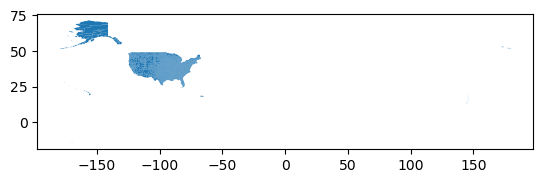

In [23]:
#d. Plot the Geo-DataFrame
counties.plot()

plt.show()

<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

### 6.B. Cleaning

Simplify column names as needed.

In [24]:
# Make column names lowercase
counties.columns = counties.columns.str.lower().str.strip()

# Verify it worked
counties.columns

Index(['statefp', 'countyfp', 'countyns', 'geoid', 'geoidfq', 'name',
       'namelsad', 'lsad', 'classfp', 'mtfcc', 'csafp', 'cbsafp', 'metdivfp',
       'funcstat', 'aland', 'awater', 'intptlat', 'intptlon', 'geometry'],
      dtype='object')

<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

### 6.C. Data selection

Select all the counties for the state of New York in a new variable `ny_counties` and plot them (you may need to look at the metadata).

In [25]:
# Subset to only New York 
ny_counties = counties[counties['statefp'] == '36']

# View Geo-DataFrame
ny_counties

,statefp,countyfp,countyns,geoid,geoidfq,name,namelsad,lsad,classfp,mtfcc,csafp,cbsafp,metdivfp,funcstat,aland,awater,intptlat,intptlon,geometry
258,36,029,00974113,36029,0500000US36029,Erie,Erie County,06,H1,G4020,160,15380,None,A,2700743371,476876406,+42.7527590,-078.7781922,"POLYGON ((-78.77760 42.46188, -78.77756 42.461..."
259,36,063,00974130,36063,0500000US36063,Niagara,Niagara County,06,H1,G4020,160,15380,None,A,1352876142,1598772310,+43.2726719,-078.8129431,"POLYGON ((-78.49165 43.08396, -78.49179 43.084..."
338,36,045,00974121,36045,0500000US36045,Jefferson,Jefferson County,06,H1,G4020,None,48060,None,A,3283928401,1524534721,+43.9963890,-076.0529678,"POLYGON ((-75.90417 43.69796, -75.90437 43.697..."
352,36,101,00974148,36101,0500000US36101,Steuben,Steuben County,06,H1,G4020,236,18500,None,A,3601403364,35034920,+42.2667252,-077.3855253,"POLYGON ((-77.08327 42.00002, -77.09391 41.999..."
492,36,099,00974147,36099,0500000US36099,Seneca,Seneca County,06,H1,G4020,464,42900,None,A,838377561,172813845,+42.7822943,-076.8270880,"POLYGON ((-76.96393 43.01284, -76.96393 43.012..."
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2792,36,003,00974100,36003,0500000US36003,Allegany,Allegany County,06,H1,G4020,None,None,None,A,2666410162,12989705,+42.2478532,-078.0261531,"POLYGON ((-78.04342 42.51846, -78.04326 42.518..."
2829,36,017,00974107,36017,0500000US36017,Chenango,Chenango County,06,H1,G4020,None,None,None,A,2314006867,13433903,+42.4780238,-075.6022407,"POLYGON ((-75.40346 42.50870, -75.40331 42.508..."
3020,36,121,00974158,36121,0500000US36121,Wyoming,Wyoming County,06,H1,G4020,None,None,None,A,1535086368,9085227,+42.7013652,-078.2285762,"POLYGON ((-77.95538 42.71354, -77.95537 42.713..."
3110,36,033,00974115,36033,0500000US36033,Franklin,Franklin County,06,H1,G4020,None,None,None,A,4219867377,176612003,+44.5943758,-074.3106700,"POLYGON ((-74.38487 44.11157, -74.38667 44.111..."


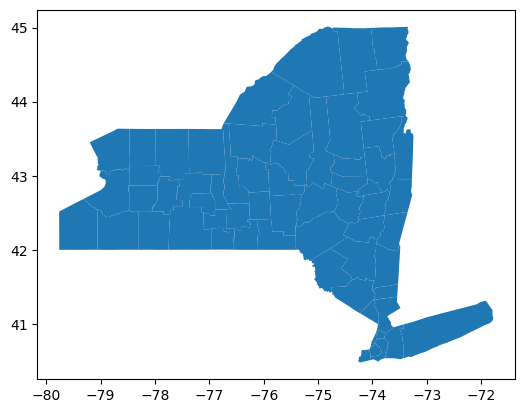

In [26]:
# Plot New York counties
ny_counties.plot()

plt.show()

<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

## 7 Merging

The goal of this section is to create a single dataframe with the number of spills per county and the corresponding geometries for each county.

### 7.A. Explore data

In the next cells:

a. Print the names of counties in `ny_counties`, without repetition.


In [27]:
# Print counties in ny_counties DataFrame
print(ny_counties['name'].unique())

['Erie' 'Niagara' 'Jefferson' 'Steuben' 'Seneca' 'Rensselaer' 'Albany'
 'Saratoga' 'Schoharie' 'Schenectady' 'Ulster' 'Dutchess' 'Orange'
 'Columbia' 'Tompkins' 'Tioga' 'Broome' 'Cayuga' 'Genesee' 'Onondaga'
 'Oswego' 'Madison' 'Livingston' 'Monroe' 'Ontario' 'Orleans' 'Wayne'
 'Chautauqua' 'Sullivan' 'Chemung' 'Cattaraugus' 'Fulton' 'Montgomery'
 'Cortland' 'Warren' 'Washington' 'Otsego' 'Queens' 'Bronx' 'Nassau'
 'Westchester' 'Richmond' 'Kings' 'Suffolk' 'Rockland' 'New York' 'Putnam'
 'Clinton' 'St. Lawrence' 'Herkimer' 'Oneida' 'Yates' 'Greene' 'Schuyler'
 'Delaware' 'Hamilton' 'Lewis' 'Allegany' 'Chenango' 'Wyoming' 'Franklin'
 'Essex']


<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

b. Print the names of counties in `spills_per_county`, without repetition. Examine the differences in the outputs.

In [28]:
# Print counties in spill_per_county DataFrame
print(spills_per_county['county'].unique())

['Albany' 'Allegany' 'Bronx' 'Broome' 'Cattaraugus' 'Cayuga' 'Chautauqua'
 'Chemung' 'Chenango' 'Clinton' 'Columbia' 'Cortland' 'Delaware'
 'Dutchess' 'Erie' 'Essex' 'Franklin' 'Fulton' 'Genesee' 'Greene'
 'Hamilton' 'Herkimer' 'Jefferson' 'Kings' 'Lewis' 'Livingston' 'Madison'
 'Monroe' 'Montgomery' 'Nassau' 'New Jersey - Region 2' 'New York'
 'Niagara' 'Oneida' 'Onondaga' 'Onondaga Indian Reservation' 'Ontario'
 'Orange' 'Orleans' 'Oswego' 'Otsego' 'Pennsylvania - Region 3' 'Putnam'
 'Queens' 'Rensselaer' 'Richmond' 'Rockland' 'Saratoga' 'Schenectady'
 'Schoharie' 'Schuyler' 'Seneca' 'St Lawrence' 'Steuben' 'Suffolk'
 'Sullivan' 'Tioga' 'Tompkins' 'Tuscarora Indian Reservation' 'Ulster'
 'Warren' 'Washington' 'Wayne' 'Westchester' 'Wyoming' 'Yates']


<!-- END QUESTION -->



c. Which are the county names that are in `spills_per_county`, but not in `ny_counties`? Your answer should be a list of strings
HINT: You can use the `numpy` function [`setdiff1d()`](https://numpy.org/doc/stable/reference/generated/numpy.setdiff1d.html), pay attention to the example in the documentation. Store your answer in the `diff_names` variable. 


In [29]:
# County names that are in spills_per_county but not in ny_counties
diff_names_spills = np.setdiff1d(spills_per_county['county'], ny_counties['name'])

# Verify it worked
diff_names_spills


array(['New Jersey - Region 2', 'Onondaga Indian Reservation',
       'Pennsylvania - Region 3', 'St Lawrence',
       'Tuscarora Indian Reservation'], dtype=object)

In [30]:
grader.check("7Ac")

7Ac results: All test cases passed!

d. Which are the county names that are in `ny_counties`, but not in `spills_per_county`? Your answer should be a list of a string/strings.


In [31]:
# Check which counties are in ny_counties but not in spills_per_county 
diff_names_ny = np.setdiff1d(ny_counties['name'], spills_per_county['county'])

# Verify it worked
diff_names_ny

array(['St. Lawrence'], dtype=object)

In [32]:
grader.check("7Ad")

7Ad results: All test cases passed!

e. What is the number of spills in 'Tuscarora Indian Reservation' and in 'Onondaga Indian Reservation'?

In [33]:
# e. Count number of spills in Tuscarora Indian Reservation and Onondaga Indian Reservation
tuscarora = spills_per_county.loc[spills_per_county['county'] == 'Tuscarora Indian Reservation', 'n_spills'].sum()
onondaga = spills_per_county.loc[spills_per_county['county'] == 'Onondaga Indian Reservation', 'n_spills'].sum()

# Use F-strings to print n_spills in each reservation
print(f"Tuscarora Indian Reservation has {tuscarora} spills.")
print(f"Onondaga Indian Reservation has {onondaga} spills.")

Tuscarora Indian Reservation has 2 spills.
Onondaga Indian Reservation has 1 spills.


### 7.B. Data updates

In the next cell, update 'St Lawrence' to 'St. Lawrence' in the `spills_per_county` data frame. Verify the update was successful with an assert test. 


In [34]:
# Create dictionary
lawr_rename = {'St Lawrence' : 'St. Lawrence'}

# Update St Lawrence to St. Lawrence in county column
spills_per_county['county'] = spills_per_county['county'].replace(lawr_rename)

# Verify it worked using assert
assert 'St. Lawrence' in spills_per_county['county'].values

### 7.C. Merge

In the following cells:

a. Use this cell to make any other updates needed for making an inner join of the `spills_per_county` and `ny_counties`. HINT: [`pd.merge`](https://pandas.pydata.org/pandas-docs/version/2.3/reference/api/pandas.merge.html)


In [35]:
# Rename column name to make consistent
ny_counties = ny_counties.rename(columns = {'name':'county'})

b. Store the inner join of the `spills_per_county` and `ny_counties` dataframes in a new variable named `ny_spills`.


In [36]:
# Create new variable of joined DataFrames
ny_spills = pd.merge(ny_counties, spills_per_county, how = 'inner', on = 'county')

# View new Geo-DataFrame
ny_spills

,statefp,countyfp,countyns,geoid,geoidfq,county,namelsad,lsad,classfp,mtfcc,csafp,cbsafp,metdivfp,funcstat,aland,awater,intptlat,intptlon,geometry,n_spills
0,36,029,00974113,36029,0500000US36029,Erie,Erie County,06,H1,G4020,160,15380,None,A,2700743371,476876406,+42.7527590,-078.7781922,"POLYGON ((-78.77760 42.46188, -78.77756 42.461...",320
1,36,063,00974130,36063,0500000US36063,Niagara,Niagara County,06,H1,G4020,160,15380,None,A,1352876142,1598772310,+43.2726719,-078.8129431,"POLYGON ((-78.49165 43.08396, -78.49179 43.084...",97
2,36,045,00974121,36045,0500000US36045,Jefferson,Jefferson County,06,H1,G4020,None,48060,None,A,3283928401,1524534721,+43.9963890,-076.0529678,"POLYGON ((-75.90417 43.69796, -75.90437 43.697...",114
3,36,101,00974148,36101,0500000US36101,Steuben,Steuben County,06,H1,G4020,236,18500,None,A,3601403364,35034920,+42.2667252,-077.3855253,"POLYGON ((-77.08327 42.00002, -77.09391 41.999...",77
4,36,099,00974147,36099,0500000US36099,Seneca,Seneca County,06,H1,G4020,464,42900,None,A,838377561,172813845,+42.7822943,-076.8270880,"POLYGON ((-76.96393 43.01284, -76.96393 43.012...",27
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
57,36,003,00974100,36003,0500000US36003,Allegany,Allegany County,06,H1,G4020,None,None,None,A,2666410162,12989705,+42.2478532,-078.0261531,"POLYGON ((-78.04342 42.51846, -78.04326 42.518...",32
58,36,017,00974107,36017,0500000US36017,Chenango,Chenango County,06,H1,G4020,None,None,None,A,2314006867,13433903,+42.4780238,-075.6022407,"POLYGON ((-75.40346 42.50870, -75.40331 42.508...",44
59,36,121,00974158,36121,0500000US36121,Wyoming,Wyoming County,06,H1,G4020,None,None,None,A,1535086368,9085227,+42.7013652,-078.2285762,"POLYGON ((-77.95538 42.71354, -77.95537 42.713...",27
60,36,033,00974115,36033,0500000US36033,Franklin,Franklin County,06,H1,G4020,None,None,None,A,4219867377,176612003,+44.5943758,-074.3106700,"POLYGON ((-74.38487 44.11157, -74.38667 44.111...",55


<!-- BEGIN QUESTION -->

c. An inner join only keeps the rows whose `county` appears in both dataframes, and it does not warn you about the rows it drops. Which records from `spills_per_county` were dropped by the inner join, and how many spills did each one have? Add the cells you need to find the dropped records.

In [37]:
# See how many unique values different between the two DataFrames
print(spills_per_county['county'].nunique())
print(ny_spills['county'].nunique())

# Check which counties are in spills_per_county but not in ny_spills 
diff_names_spills = np.setdiff1d(spills_per_county['county'], ny_spills['county'])

# Verify which counties were dropped
print(diff_names_spills)

# Create for-loop to sum spills in missing counties
for county in diff_names_spills: 
    dropped_spill = spills_per_county.loc[spills_per_county['county'] == county, 'n_spills'].sum() 
    print(f"{county} had {dropped_spill} spills")

66
62
['New Jersey - Region 2' 'Onondaga Indian Reservation'
 'Pennsylvania - Region 3' 'Tuscarora Indian Reservation']
New Jersey - Region 2 had 7 spills
Onondaga Indian Reservation had 1 spills
Pennsylvania - Region 3 had 1 spills
Tuscarora Indian Reservation had 2 spills


<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

d. Does dropping these records affect the map or the information we will report? Write your answer in the following markdown cell.

> Dropping these records does not change the map’s coverage, since all 62 New York counties still appear. However, it does affect the information we report. The Tuscarora and Onondaga Indian Reservations are located within Niagara and Onondaga counties, so excluding their combined 3 spills underrepresents those two counties. The New Jersey and Pennsylvania records represent spills that also affected these areas, so because they are outside New York’s county boundaries, excluding them from a county-level map is reasonable.

<!-- END QUESTION -->


From our previous exploration we know that Tuscarora Indian Reservation and Onondaga Indian Reservation will not be in the join. Tuscarora Indian Reservation is located within Niagara county and Onondaga Indian Reservation is located within Onondaga county. 

e. Since the reservations do not appear in the `ny_counties` dataframe, add the Tuscarora Indian Reservation spills to Niagara county and the Onondaga Indian Reservation spills to Onondaga county in `ny_spills`. We will add a note about this in our final map, and we will reflect on this choice in exercise 8.b. Add the cells you need to make this update **and** verify that the dataframe was updated.

In [38]:
# Save original counts for assert verification
tusc_n_spill = ny_spills.loc[ny_spills['county'] == 'Niagara', 'n_spills'].sum()
print(tusc_n_spill)
      
ono_n_spill = ny_spills.loc[ny_spills['county'] == 'Onondaga', 'n_spills'].sum()
print(ono_n_spill)

# Getting the number of spills in Tuscarora
tusc_spills = spills_per_county.loc[spills_per_county['county'] == 'Tuscarora Indian Reservation', 'n_spills'].sum()
print(tusc_spills)

# Adding these spills to Niagara county in ny_spills
ny_spills.loc[ny_spills['county'] == 'Niagara', 'n_spills'] = ny_spills.loc[ny_spills['county'] == 'Niagara', 'n_spills'] + tusc_spills

# Getting the number of spills in Onondaga
ono_spills = spills_per_county.loc[spills_per_county['county'] == 'Onondaga Indian Reservation', 'n_spills'].sum()
print(ono_spills)

# Adding these spills to Onondaga county in ny_spills
ny_spills.loc[ny_spills['county'] == 'Onondaga', 'n_spills'] = ny_spills.loc[ny_spills['county'] == 'Onondaga', 'n_spills'] + ono_spills

97
214
2
1


In [39]:
# Verify the update with assert
assert ny_spills.loc[ny_spills['county'] == 'Niagara', 'n_spills'].sum() == tusc_n_spill + tusc_spills, "Niagara was not updated correctly"
assert ny_spills.loc[ny_spills['county'] == 'Onondaga', 'n_spills'].sum() == ono_n_spill + ono_spills, "Onondaga was not updated correctly"

## 8. Map
a. Create a choropleth map of the number of petroleum spills per county in the state of New York in 2023. 
Your map should be polished and have (at least) the following updates:
- a legend indicating the number of spills
- an updated color map
- a title 
- no axis
- an annotation with the data source (New York State Department of Environmental Conservation) and date of access



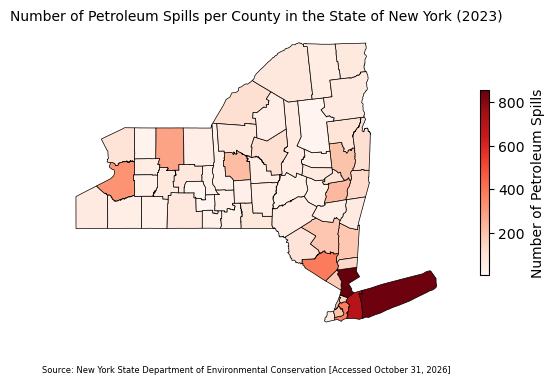

In [40]:

# Initialize empty figure and axes
fig, ax = plt.subplots()

# Plot petroleum spills in New York
ny_spills.plot(column = 'n_spills',                                                          # specify which value to plot
               cmap = 'Reds',                                                                # specify color scheme
               edgecolor = 'Black',                                                          # customizing county boundary color
               linewidth = 0.5,                                                              # customizing line width
               legend = True,                                                                # adding legend
               legend_kwds={'label': 'Number of Petroleum Spills', 'shrink' : 0.5},          # adding title to legend and changing size
               ax = ax)                     


# Remove axis
ax.axis('off')

# Add title
ax.set_title('Number of Petroleum Spills per County in the State of New York (2023)', fontsize = 10)

# Add data source
fig.text(0.1, 0.1, 'Source: New York State Department of Environmental Conservation [Accessed October 31, 2026]', fontsize = 6)

# Display map
plt.show()



b. Write a description of how the map was created, including key takeaways. If you need to do additional data analysis to include relevant information from the data, you may include additional cells here.

In your description, also reflect on how we handled the spills reported in the Tuscarora and Onondaga Indian Reservations (exercise 7.C.e) in terms of data governance and the CARE Principles for Indigenous Data Governance from Task 1.

In [41]:
# Seeing which county reported the most spills (top3)
ny_spills.sort_values('n_spills', ascending=False)[['county', 'n_spills']].head(3)

,county,n_spills
40,Westchester,855
43,Suffolk,845
39,Nassau,698


> To create this map, we filtered the New York State Department of Environmental Conservation’s Spill Incidents data to petroleum spills reported in 2023 and counted the unique spills in each county. We then joined these counts to the 2026 TIGER county boundaries for New York and plotted them as a choropleth map. The map shows that petroleum spills were concentrated in the southern region. Suffolk and Westchester counties each recorded over 800 spills, and Nassau County had 698. Most upstate counties had far fewer spills, though there were some counties that stood out as moderate hotspots.

> Because an inner join silently drops unmatched rows, we checked which records were excluded. Four did not match: two out-of-state regions (New Jersey and Pennsylvania), which were excluded because they fall outside New York’s county boundaries, and the Tuscarora and Onondaga Indian Reservations. The reservations did not match because they are sovereign nations rather than counties, so they do not appear in the county boundary data. To keep their 3 spills from disappearing, we added them to the counts for their respected counties, which are Niagara and Onondaga counties.

> From a CARE Principles perspective, this choice deserves attention. Merging the reservations into neighboring counties kept their spills in the analysis, but it also absorbed two sovereign nations into state counties, a decision made without input from the Tuscarora or Onondaga Nations. This conflicts with the principle of "Authority to Control", which holds that Indigenous peoples should govern how data about their lands is represented. An alternative would have been to map the reservations as their own areas. Even with only 3 spills, this example shows how routine data cleaning decisions can make Indigenous lands invisible unless researchers deliberately check for them.

## Complete workflow

Collect all the relevant code into the first blank cell of the notebook titled "COMPLETE WORKFLOW". This single cell will have the end-to-end workflow: from importing libraries and loading the data, to producing the choropleth map of the number of petroleum spills per county in the state of New York in 2023. The only output of this cell should be the choropleth map  you produced in the previous exercise. Further guidance on what to include in this final workflow is in the assignment rubric.